
# An?lisis exploratorio de datos (EDA) ? Mercado de motos en Cuba

Exploraci?n de los anuncios de **Revolico (La Habana)** ya limpiados con
`src/limpieza_datos/limpiar_revolico.py`.

Preguntas de an?lisis:
1. ?C?mo se distribuyen los precios de las motos **el?ctricas** frente a las de **combusti?n**?
2. ?Qu? tipos de veh?culos hay y en cu?les el precio es m?s alto?
3. ?Qu? **marcas** dominan la oferta?
4. ?D?nde est?n los **precios anormalmente altos**?


In [1]:
#%matplotlib inline
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

REPO = Path.cwd().parent          # el notebook vive en notebooks/
GRAF = REPO / "graficos"
GRAF.mkdir(exist_ok=True)

limpios = sorted((REPO / "datos" / "limpios").glob("revolico_limpio_*.json"))
if not limpios:
    raise SystemExit("Faltan datos limpios. Ejecuta primero src/limpieza_datos/limpiar_revolico.py")
print("Usando:", limpios[-1].name)

df = pd.DataFrame(json.loads(limpios[-1].read_text(encoding="utf-8"))["registros"])
df["precio"] = pd.to_numeric(df["precio"], errors="coerce")
print("Registros cargados:", len(df))
df[["categoria_clave", "tipo_vehiculo", "marca", "titulo", "precio", "url"]].head()


Usando: revolico_limpio_20261017_1209.json


Registros cargados: 6466


,categoria_clave,tipo_vehiculo,marca,titulo,precio,url
0,motos_electricas,otro,MAF,BICIMOTO MAF,1150.0,https://www.revolico.com/item/bicimoto-maf-579...
1,motos_electricas,otro,MOTICO,MOTICO DCMLZ B1,850.0,https://www.revolico.com/item/motico-dcmlz-b1-...
2,motos_electricas,otro,MIKAZUKI,MOTICO MIKAZUKI 2026,1000.0,https://www.revolico.com/item/motico-mikazuki-...
3,motos_electricas,bicicleta_electrica,SIN_MARCA,Bicicleta Eléctrica Ebike,1200.0,https://www.revolico.com/item/bicicleta-electr...
4,motos_electricas,bicimoto_electrica,PROTENZZA,Bicimoto eléctrica PROTENZZA,770.0,https://www.revolico.com/item/bicimoto-electri...


## 1. Vista general y limpieza de precios

In [2]:
df_valid = df[df["precio_valido"] == True].copy()
print(f"Precios v?lidos (>= 100 USD): {len(df_valid)} de {len(df)} registros")
print("Monedas:", df["moneda"].value_counts().to_dict())

por_categoria = df.groupby("categoria_clave").size().rename("anuncios")
por_categoria


Precios v?lidos (>= 100 USD): 5962 de 6466 registros


Monedas: {'USD': 6428, 'CUP': 38}


categoria_clave
motos_combustion    1172
motos_electricas    5294
Name: anuncios, dtype: int64

In [3]:
resumen = (
    df_valid.groupby("tipo_vehiculo")["precio"]
    .describe(percentiles=[.25, .5, .75])[["count", "min", "25%", "50%", "75%", "max"]]
    .round(0)
    .rename(columns={"50%": "mediana"})
    .sort_values("mediana", ascending=False)
)
resumen


,count,min,25%,mediana,75%,max
tipo_vehiculo,,,,,,
moto_electrica,1379.0,100.0,1650.0,2400.0,2700.0,20000.0
combustion_scooter,22.0,800.0,2018.0,2300.0,2300.0,4500.0
combustion,953.0,110.0,1890.0,2300.0,2600.0,50000.0
combustion_deportiva,100.0,1850.0,2100.0,2300.0,2600.0,20000.0
otro,2095.0,100.0,850.0,1550.0,1850.0,111111.0
electrico_sin_clasificar,139.0,125.0,595.0,1490.0,3600.0,35000.0
bicimoto_electrica,287.0,100.0,800.0,1450.0,1700.0,2600.0
patinete_electrico,166.0,100.0,672.0,750.0,790.0,1250.0
bicicleta_electrica,821.0,100.0,500.0,590.0,850.0,1920.0



## 2. Distribuci?n de precios: el?ctricas vs combusti?n

El histograma compara cu?ntos anuncios hay en cada tramo de precio.


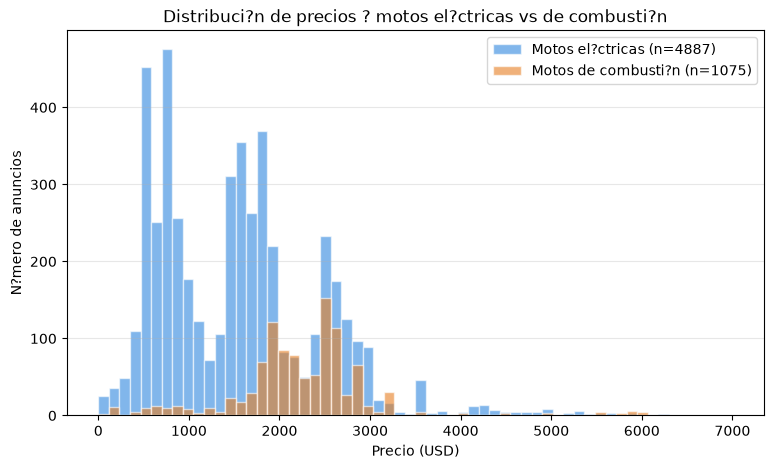

Gr?fico guardado en: C:\Users\LA RUEDA\Desktop\Proyecto de ICD Motos en cuba (2)\Mercado-de-Motos\graficos\distribucion_precios.png


In [4]:
NOMBRES = {"motos_electricas": "Motos el?ctricas",
            "motos_combustion": "Motos de combusti?n"}
COLORES = {"motos_electricas": "#2E86DE",
           "motos_combustion": "#E67E22"}

fig, ax = plt.subplots(figsize=(9, 5))
for clave, color in COLORES.items():
    datos = df_valid[df_valid["categoria_clave"] == clave]["precio"]
    ax.hist(datos, bins=60, range=(0, 7000), alpha=0.6, color=color,
            label=f"{NOMBRES[clave]} (n={len(datos)})", edgecolor="white")

ax.set_xlabel("Precio (USD)")
ax.set_ylabel("N?mero de anuncios")
ax.set_title("Distribuci?n de precios ? motos el?ctricas vs de combusti?n")
ax.legend()
ax.grid(axis="y", alpha=0.3)

ruta = GRAF / "distribucion_precios.png"
fig.savefig(ruta, dpi=130, bbox_inches="tight")
plt.show()
print("Gr?fico guardado en:", ruta)



## 3. Comparaci?n por tipo de veh?culo (diagrama de cajas)

La caja va del cuartil 1 al 3; la l?nea es la mediana. Los "bigotes" llegan a
1,5 ? rango intercuart?lico.


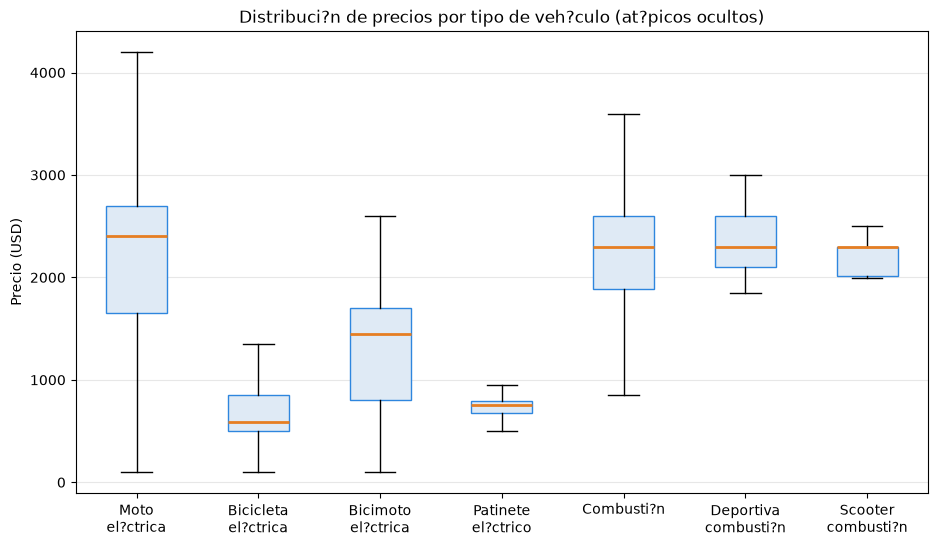

Gr?fico guardado en: C:\Users\LA RUEDA\Desktop\Proyecto de ICD Motos en cuba (2)\Mercado-de-Motos\graficos\precios_por_tipo.png


In [5]:
TIPOS = ["moto_electrica", "bicicleta_electrica", "bicimoto_electrica",
          "patinete_electrico", "combustion", "combustion_deportiva", "combustion_scooter"]
ETIQUETAS = {"moto_electrica": "Moto\nel?ctrica",
             "bicicleta_electrica": "Bicicleta\nel?ctrica",
             "bicimoto_electrica": "Bicimoto\nel?ctrica",
             "patinete_electrico": "Patinete\nel?ctrico",
             "combustion": "Combusti?n",
             "combustion_deportiva": "Deportiva\ncombusti?n",
             "combustion_scooter": "Scooter\ncombusti?n"}

sub = df_valid[df_valid["tipo_vehiculo"].isin(TIPOS)]
cajas = [sub[sub["tipo_vehiculo"] == t]["precio"].dropna() for t in TIPOS]

fig, ax = plt.subplots(figsize=(11, 6))
ax.boxplot(cajas, showfliers=False, patch_artist=True,
           boxprops=dict(facecolor="#dfeaf5", color="#2E86DE"),
           medianprops=dict(color="#E67E22", linewidth=2))
ax.set_xticks(range(1, len(TIPOS) + 1))
ax.set_xticklabels([ETIQUETAS[t] for t in TIPOS])
ax.set_ylabel("Precio (USD)")
ax.set_title("Distribuci?n de precios por tipo de veh?culo (at?picos ocultos)")
ax.grid(axis="y", alpha=0.3)

ruta = GRAF / "precios_por_tipo.png"
fig.savefig(ruta, dpi=130, bbox_inches="tight")
plt.show()
print("Gr?fico guardado en:", ruta)



## 4. Proporci?n de mercado: el?ctricas frente a combusti?n

De los anuncios publicados, ?qu? porcentaje corresponde a cada tipo?


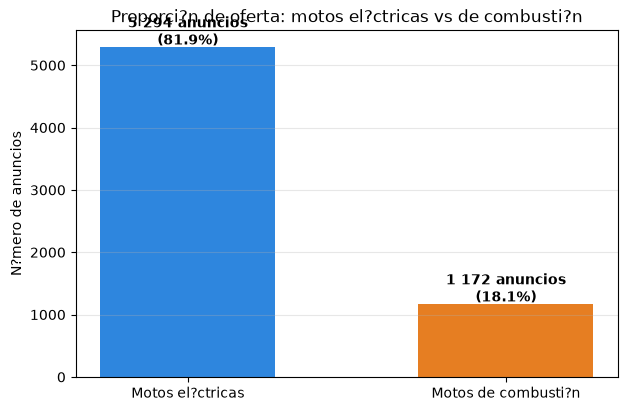

,anuncios,%
categoria_clave,,
Motos el?ctricas,5294,81.9
Motos de combusti?n,1172,18.1


In [6]:
conteo = df["categoria_clave"].map(NOMBRES).value_counts()
porcentaje = (conteo / conteo.sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(7, 4.5))
barras = ax.bar(conteo.index, conteo.values, color=[COLORES["motos_electricas"],
                                                    COLORES["motos_combustion"]], width=0.55)
for barra, total, pct in zip(barras, conteo.values, porcentaje.values):
    ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 40,
            f"{total:,} anuncios\n({pct}%)".replace(",", " "), ha="center",
            fontweight="bold")

ax.set_ylabel("N?mero de anuncios")
ax.set_title("Proporci?n de oferta: motos el?ctricas vs de combusti?n")
ax.grid(axis="y", alpha=0.3)

ruta = GRAF / "proporcion_mercado.png"
fig.savefig(ruta, dpi=130, bbox_inches="tight")
plt.show()
pd.DataFrame({"anuncios": conteo, "%": porcentaje})


## 5. Marcas m?s frecuentes

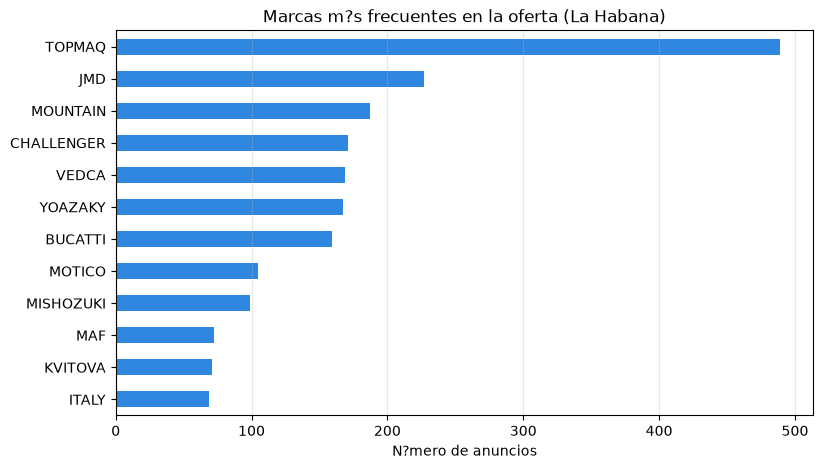

marca
TOPMAQ        489
JMD           227
MOUNTAIN      187
CHALLENGER    171
VEDCA         169
YOAZAKY       167
BUCATTI       159
MOTICO        105
MISHOZUKI      99
MAF            72
KVITOVA        71
ITALY          69
Name: count, dtype: int64

In [7]:
top_marcas = (df_valid[df_valid["marca"] != "SIN_MARCA"]["marca"].value_counts().head(12))

fig, ax = plt.subplots(figsize=(9, 5))
top_marcas.iloc[::-1].plot.barh(ax=ax, color="#2E86DE")
ax.set_xlabel("N?mero de anuncios")
ax.set_ylabel("")
ax.set_title("Marcas m?s frecuentes en la oferta (La Habana)")
ax.grid(axis="x", alpha=0.3)

ruta = GRAF / "top_marcas.png"
fig.savefig(ruta, dpi=130, bbox_inches="tight")
plt.show()
top_marcas



## 6. Precios anormalmente altos (m?todo IQR)

Un anuncio se marca como at?pico si su precio supera
`Q3 + 1,5 ? rango intercuart?lico` **dentro de su grupo**.

Los detalles completos est?n en `src/analisis/precios_atipicos.py`.


In [8]:
def atipicos(grupo, factor=1.5):
    p = df_valid[df_valid["tipo_vehiculo"] == grupo]["precio"].dropna()
    if len(p) < 4:
        return pd.DataFrame()
    q1, q3 = p.quantile(0.25), p.quantile(0.75)
    limite = q3 + factor * (q3 - q1)
    out = df_valid[(df_valid["tipo_vehiculo"] == grupo) & (df_valid["precio"] > limite)]
    return out.sort_values("precio", ascending=False)

top_atipicos = pd.concat([
    atipicos("combustion"),
    atipicos("combustion_deportiva"),
    atipicos("moto_electrica"),
    atipicos("bicicleta_electrica"),
]).sort_values("precio", ascending=False)

top_atipicos[["tipo_vehiculo", "marca", "titulo", "precio", "url"]].head(15).reset_index(drop=True)


,tipo_vehiculo,marca,titulo,precio,url
0,combustion,SIN_MARCA,Venta de motor,50000.0,https://www.revolico.com/item/venta-de-motor-5...
1,combustion,SIN_MARCA,Moto BMW S1000RR 2025,26000.0,https://www.revolico.com/item/moto-bmw-s1000rr...
2,combustion_deportiva,KAWASAKI,KAWASAKI NINJA ZX-10R 2021,20000.0,https://www.revolico.com/item/kawasaki-ninja-z...
3,moto_electrica,SIN_MARCA,"EN VENTA , Cargador d moto electrica 60v 45 Ah...",20000.0,https://www.revolico.com/item/en-venta-cargado...
4,combustion_deportiva,KAWASAKI,SE VENDE KAWASAKI NINJA ZX-10R 2021 1000 CC 4 ...,20000.0,https://www.revolico.com/item/se-vende-kawasak...
5,combustion_deportiva,KAWASAKI,Kawasaki ninja zx6r del 2024,12500.0,https://www.revolico.com/item/kawasaki-ninja-z...
6,combustion,SIN_MARCA,HONDA CBR 600RR 2012,12000.0,https://www.revolico.com/item/honda-cbr-600rr-...
7,combustion,SIN_MARCA,HONDA CBR 600RR 2012,12000.0,https://www.revolico.com/item/honda-cbr-600rr-...
8,combustion,SIN_MARCA,Se vende Gelly ck soy la durña 11500,11500.0,https://www.revolico.com/item/se-vende-gelly-c...
9,combustion,SIN_MARCA,Moto combustión IZUKI,11111.0,https://www.revolico.com/item/moto-combustion-...



## Conclusiones

1. **El mercado est? dominado por las motos el?ctricas**, que concentran la mayor?a de los anuncios publicados.
2. En **precio mediano**, las motos de combusti?n tienden a ser m?s caras que las el?ctricas y mucho m?s que las bicicletas/patinetes.
3. Las **bicicletas y patinetes el?ctricos** forman el segmento m?s econ?mico (rango estrecho de precios).
4. Existen **precios anormalmente altos** (motos deportivas de m?s de 10 000 USD, cargadores o bater?as publicados como motos), que deben tratarse aparte en el an?lisis.
